# 02 · Objetivo (ii): competências técnicas, cognitivas, socioemocionais e metacognitivas

> *"Mapear as competências técnicas, cognitivas e socioemocionais mencionadas, descrevendo sua frequência por área de atuação e nível de entrada."* (Seção 1.3, objetivo ii)

**Perguntas**
1. Quais competências aparecem com mais frequência em cada grupo de área e nível?
2. Como o resultado muda quando se controla o **tamanho do texto** (Seção 3.5)?
3. Quais habilidades técnicas dominam cada grupo, e qual o peso de **conceitos** frente a **ferramentas**? (Dobslaw et al., 2023)
4. Qual o risco de **falsos positivos** do dicionário? Planilha de validação em `validacao_dicionario_amostra.csv` (`[P11]`).

**Ligação com a literatura:** Westby et al. (2026) — comunicação e resolução de problemas em alta nas vagas júnior; Deming (2017) — habilidades sociais; WEF (2025) — pensamento analítico e aprendizagem ao longo da vida; Dobslaw et al. (2023) — conceitos vs. tecnologias.

> Dimensões do artigo: **técnica** (taxonomia do projeto, sem idiomas), **cognitiva**, **socioemocional** e **metacognitiva**. Os valores abaixo são proporções de anúncios que mencionam a competência **pelo menos uma vez**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, re
import matplotlib.patches as mp
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
CHAVES = list(L.COMPETENCIAS)
ROT = {k: v[1] for k, v in L.COMPETENCIAS.items()}
DIM = {k: v[0] for k, v in L.COMPETENCIAS.items()}
SIG = {L.COG: "C", L.SOC: "S", L.MET: "M"}
ordem_comp = sorted(CHAVES, key=lambda k: (L.DIMENSOES.index(DIM[k]), -df[f"c_{k}"].mean()))
print(f"{len(df):,} anúncios | {len(CHAVES)} competências no dicionário do artigo")

9,964 anúncios | 13 competências no dicionário do artigo


## 1. Mapa de competências por grupo de área
Cada linha é uma competência, agrupada por dimensão (C = cognitiva, S = socioemocional, M = metacognitiva).

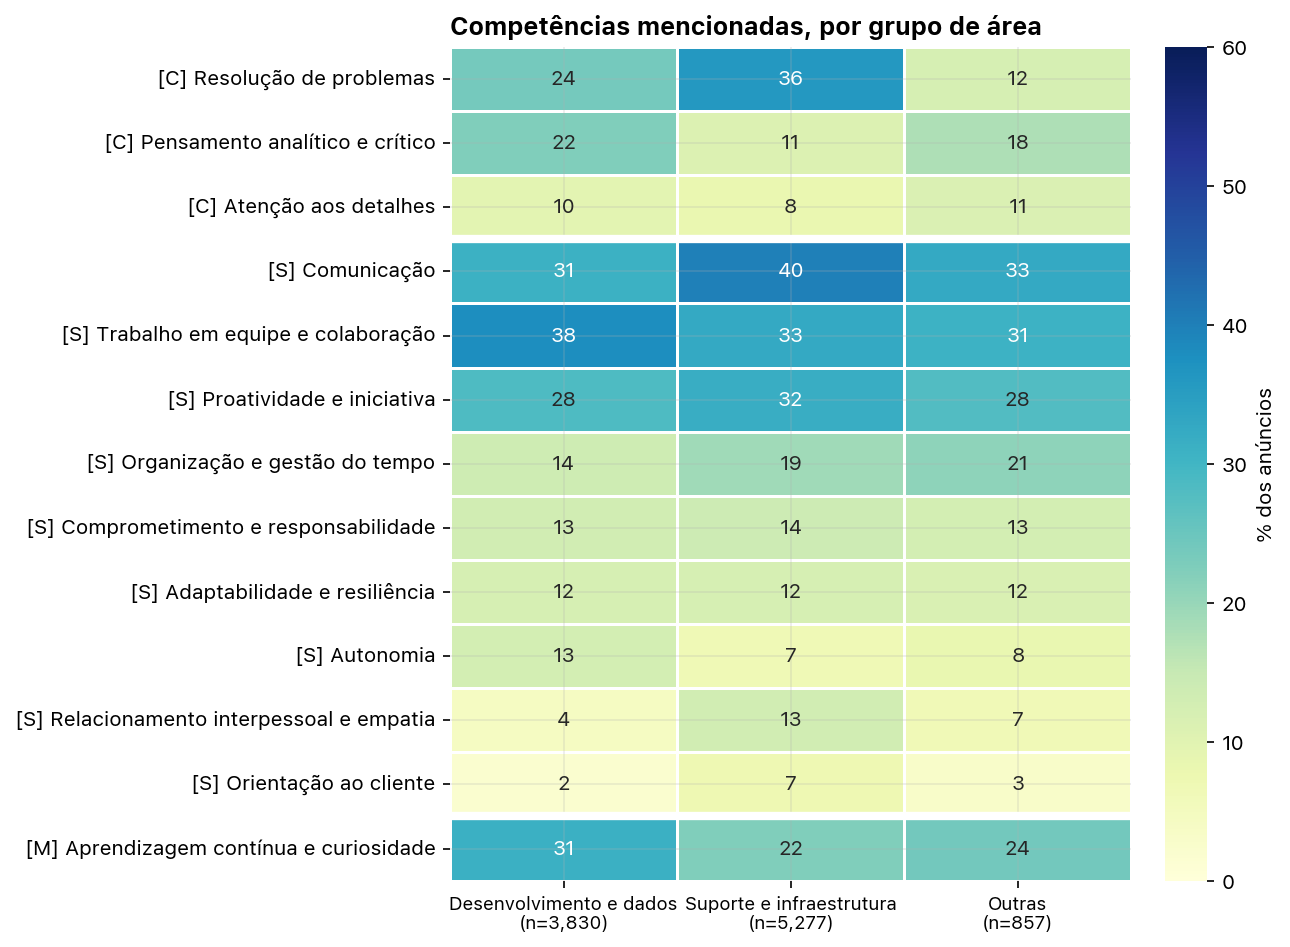

In [2]:
def matriz(sub_por, colunas):
    m = pd.DataFrame({c: [100 * s[f"c_{k}"].mean() for k in ordem_comp] for c, s in sub_por.items()}, index=ordem_comp)
    m.index = [f"[{SIG[DIM[k]]}] {ROT[k]}" for k in ordem_comp]
    return m

sub = {f"{g}\n(n={(df.grupo == g).sum():,})": df[df.grupo == g] for g in L.ORDEM_GRUPOS}
M = matriz(sub, None)
fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(M, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=60, linewidths=.5, cbar_kws={"label": "% dos anúncios"}, ax=ax)
ax.set_title("Competências mencionadas, por grupo de área"); ax.set_ylabel(""); ax.tick_params(axis="x", labelsize=9)
for y in (np.cumsum([sum(DIM[k] == d for k in ordem_comp) for d in L.DIMENSOES])[:-1]): ax.axhline(y, color="white", lw=4)
L.salvar(fig, "02_mapa_competencias_grupo"); plt.show()

## 2. Por grupo **e** nível (Estágio e Júnior)

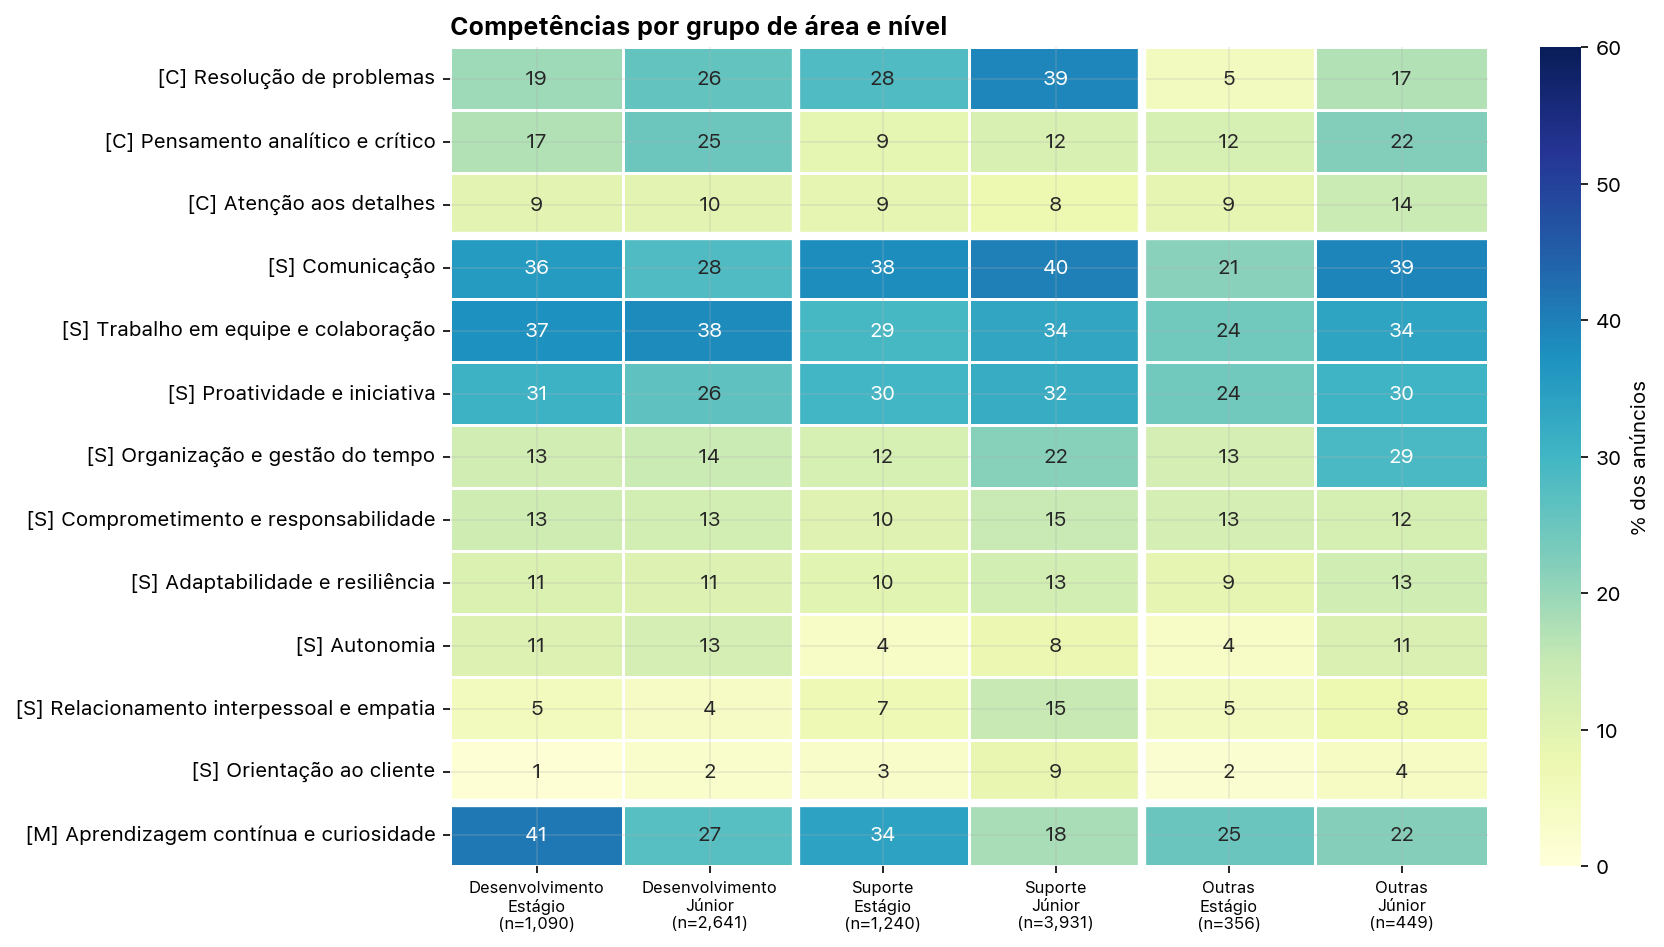

In [3]:
sub2 = {}
for g in L.ORDEM_GRUPOS:
    for nv in L.NIVEIS_PRINCIPAIS:
        s = df[(df.grupo == g) & (df.nivel == nv)]
        sub2[f"{g.split(' e ')[0]}\n{nv}\n(n={len(s):,})"] = s
M2 = matriz(sub2, None)
fig, ax = plt.subplots(figsize=(11, 6.2))
sns.heatmap(M2, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=60, linewidths=.5, cbar_kws={"label": "% dos anúncios"}, ax=ax)
ax.set_title("Competências por grupo de área e nível"); ax.set_ylabel(""); ax.tick_params(axis="x", labelsize=8)
for y in (np.cumsum([sum(DIM[k] == d for k in ordem_comp) for d in L.DIMENSOES])[:-1]): ax.axhline(y, color="white", lw=4)
for x in (2, 4): ax.axvline(x, color="white", lw=4)
L.salvar(fig, "02_mapa_competencias_grupo_nivel"); plt.show()

## 3. Padronização por quartil de tamanho do texto (Seção 3.5)

Anúncios longos citam mais coisas. A **padronização direta** recalcula a prevalência de cada grupo dando a cada quartil
de tamanho o **mesmo peso do conjunto total**. Assim, um grupo não "parece" exigir mais só porque seus anúncios são mais longos.
O gráfico mostra a **diferença entre a proporção padronizada e a bruta** (pontos percentuais).

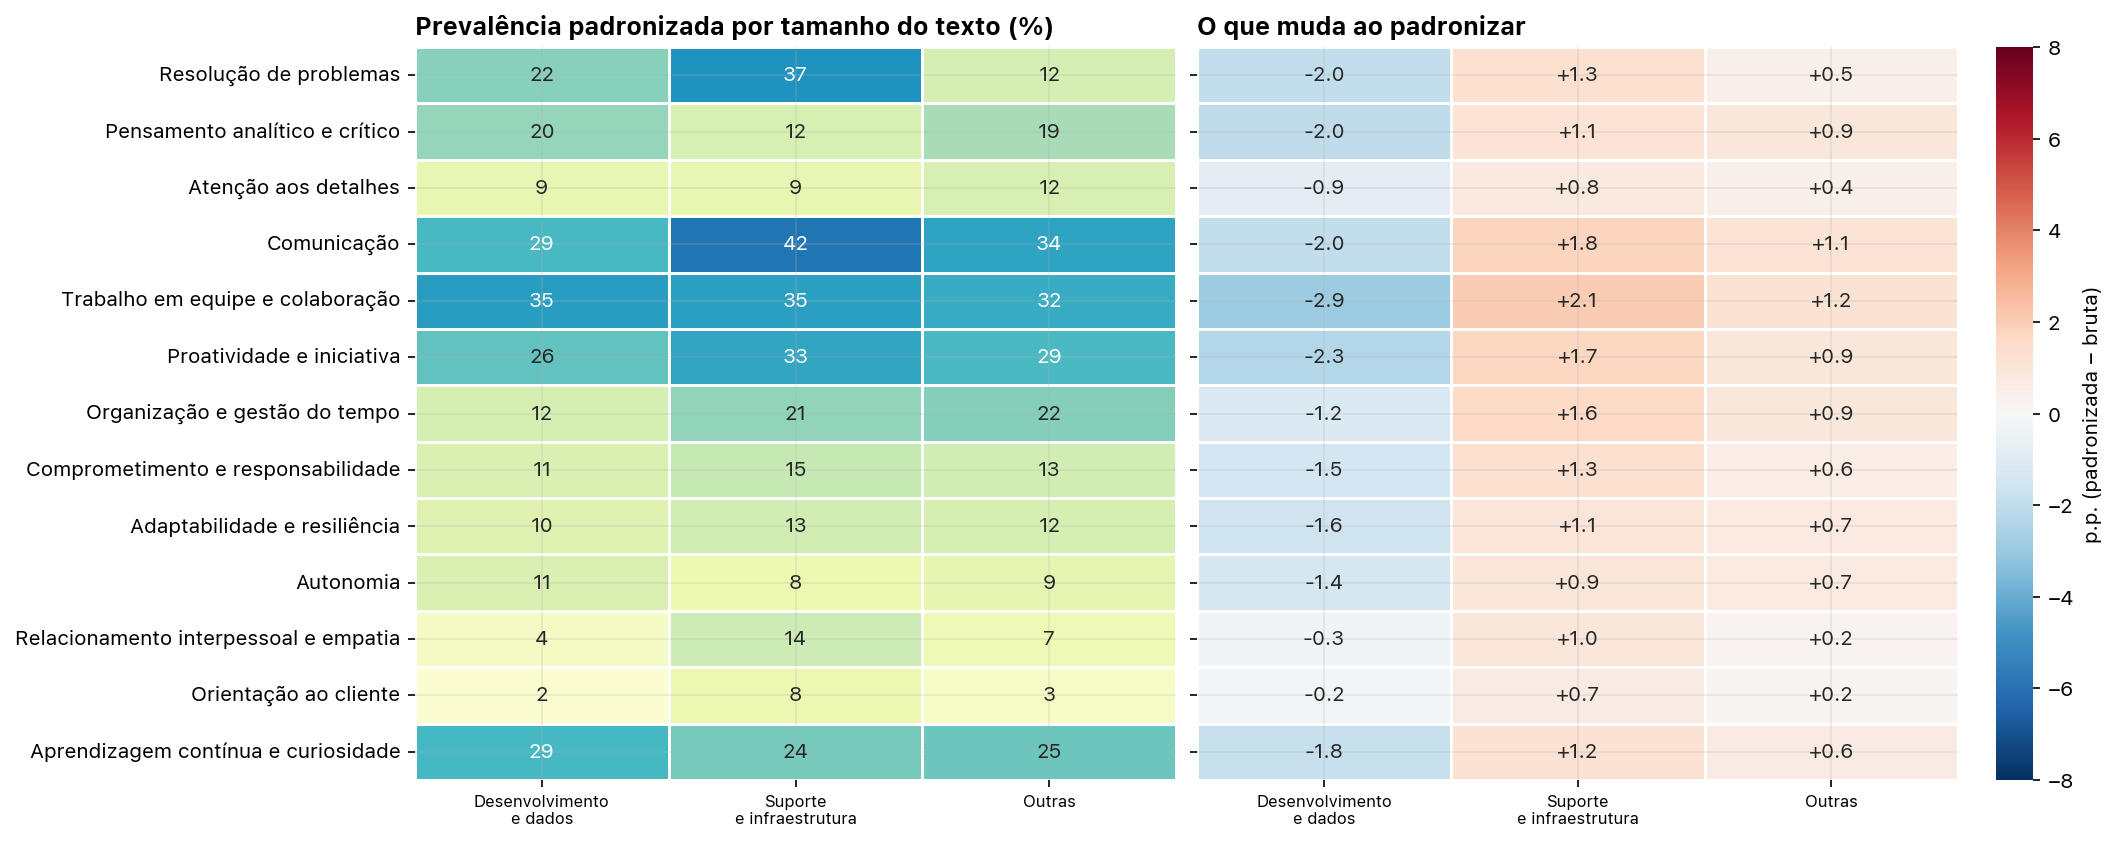

Maior ajuste absoluto: 2.9 p.p.


In [4]:
pesos = df["quartil_tam"].value_counts(normalize=True)
def prev_pad(s, col):
    pq = s.groupby("quartil_tam", observed=True)[col].mean()
    return 100 * (pq * pesos.reindex(pq.index)).sum() / pesos.reindex(pq.index).sum()

bruta = pd.DataFrame({g: [100 * df[df.grupo == g][f"c_{k}"].mean() for k in ordem_comp] for g in L.ORDEM_GRUPOS}, index=ordem_comp)
pad = pd.DataFrame({g: [prev_pad(df[df.grupo == g], f"c_{k}") for k in ordem_comp] for g in L.ORDEM_GRUPOS}, index=ordem_comp)
dif = (pad - bruta); dif.index = [ROT[k] for k in dif.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1]})
pp = pad.copy(); pp.index = [ROT[k] for k in pp.index]
sns.heatmap(pp, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=60, ax=axes[0], linewidths=.5, cbar=False)
axes[0].set_title("Prevalência padronizada por tamanho do texto (%)"); axes[0].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
sns.heatmap(dif, annot=True, fmt="+.1f", cmap="RdBu_r", center=0, vmin=-8, vmax=8, ax=axes[1], linewidths=.5, cbar_kws={"label": "p.p. (padronizada − bruta)"})
axes[1].set_title("O que muda ao padronizar"); axes[1].set_yticklabels([]); axes[1].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
L.salvar(fig, "02_padronizacao_tamanho"); plt.show()
print(f"Maior ajuste absoluto: {dif.abs().max().max():.1f} p.p.")

## 4. Quatro dimensões do artigo, por grupo (com IC 95%)
Proporção de anúncios com **ao menos uma** competência de cada dimensão.

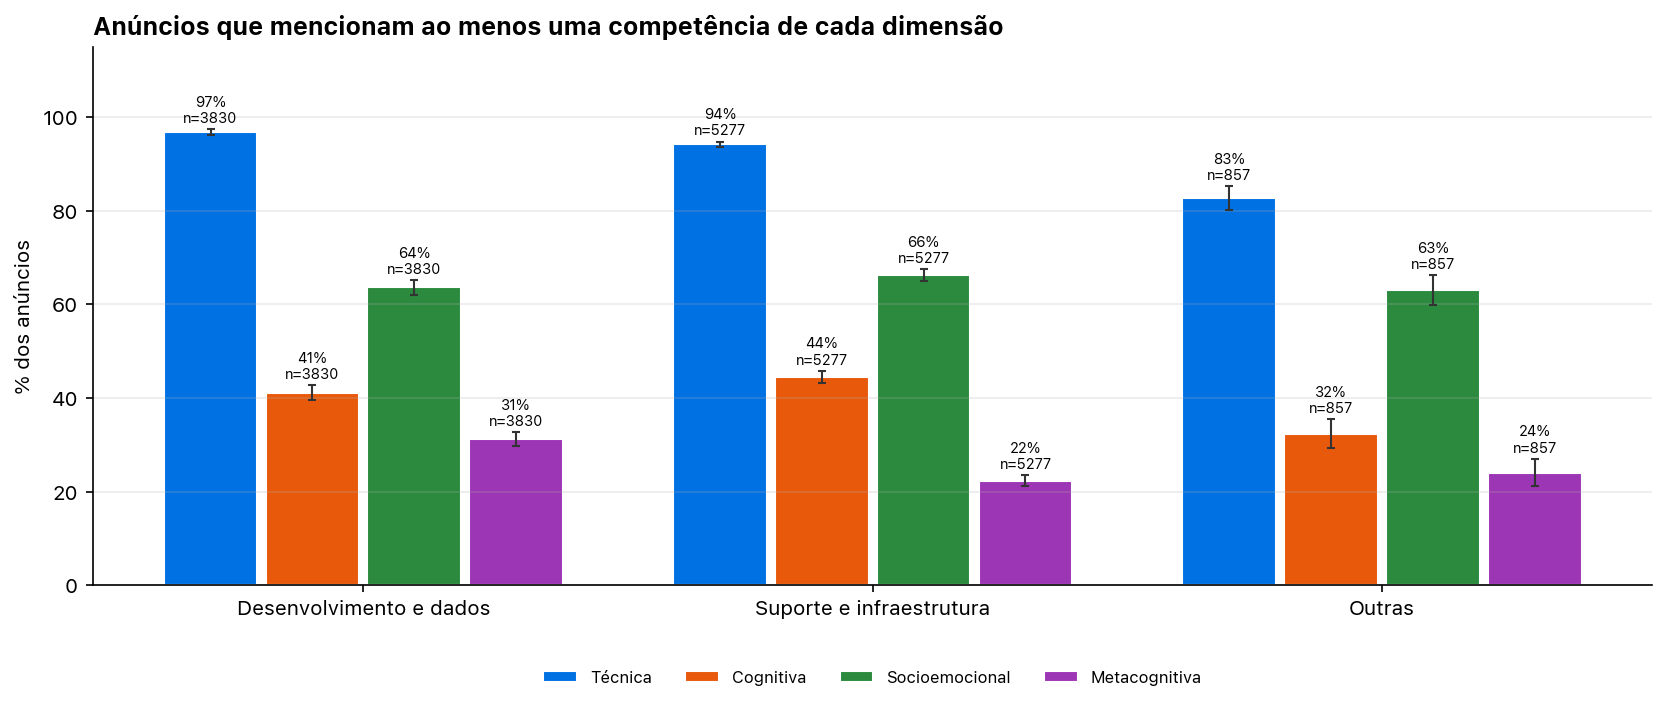

In [5]:
dims = {"d_tecnica": "Técnica", "d_cog": "Cognitiva", "d_soc": "Socioemocional", "d_met": "Metacognitiva"}
cd = {"Técnica": "#0071E3", "Cognitiva": "#E8590C", "Socioemocional": "#2B8A3E", "Metacognitiva": "#9C36B5"}
tabs = []
for c, nome in dims.items():
    t = L.tabela_prop(df, c, ["grupo"]); t["dimensao"] = nome; tabs.append(t)
td = pd.concat(tabs)
fig, ax = plt.subplots(figsize=(11, 4.6))
L.barras_prop(ax, td, "grupo", "dimensao", L.ORDEM_GRUPOS, list(dims.values()), cd)
ax.set_title("Anúncios que mencionam ao menos uma competência de cada dimensão"); ax.set_ylim(0, 115); ax.set_xlabel("")
L.salvar(fig, "02_dimensoes_grupo"); plt.show()

## 5. Quantas competências (dicionário) cada anúncio traz?

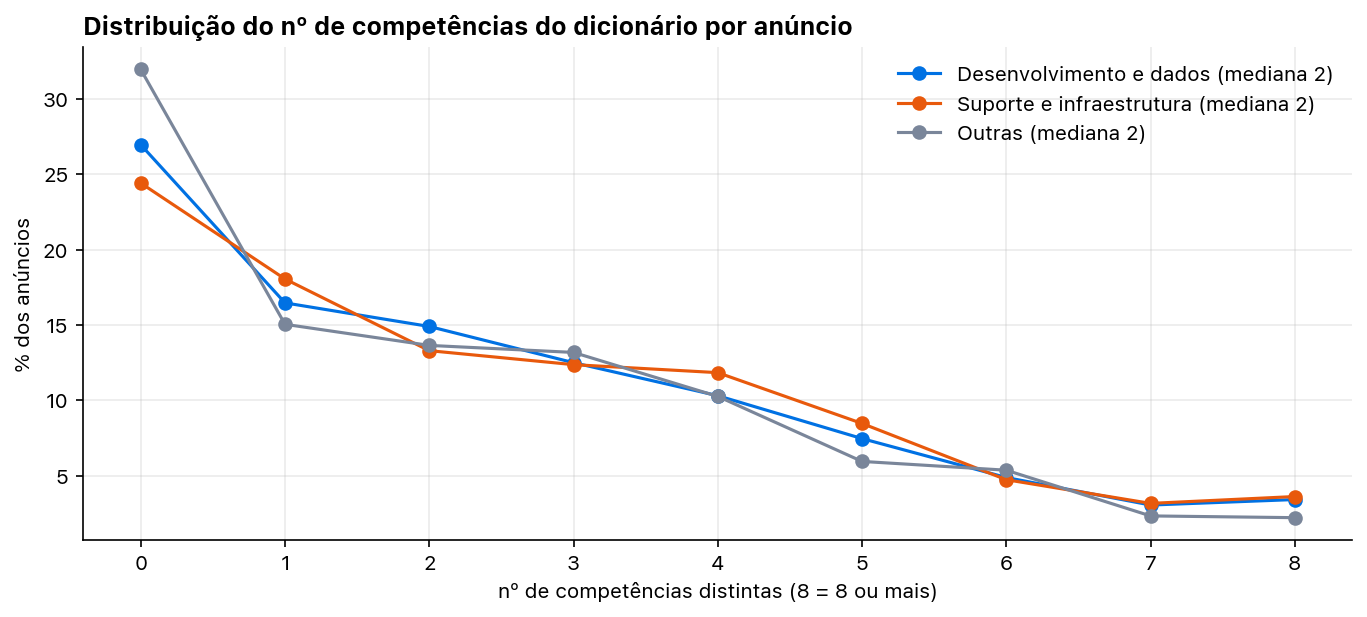

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for g in L.ORDEM_GRUPOS:
    v = df[df.grupo == g]["n_comp"].clip(upper=8).value_counts(normalize=True).sort_index() * 100
    ax.plot(v.index, v.values, marker="o", color=L.PALETA[g], label=f"{g} (mediana {df[df.grupo == g]['n_comp'].median():.0f})")
ax.set_xlabel("nº de competências distintas (8 = 8 ou mais)"); ax.set_ylabel("% dos anúncios"); ax.legend()
ax.set_title("Distribuição do nº de competências do dicionário por anúncio")
L.salvar(fig, "02_n_competencias"); plt.show()

## 6. Competências técnicas (taxonomia do projeto): top 15 por grupo

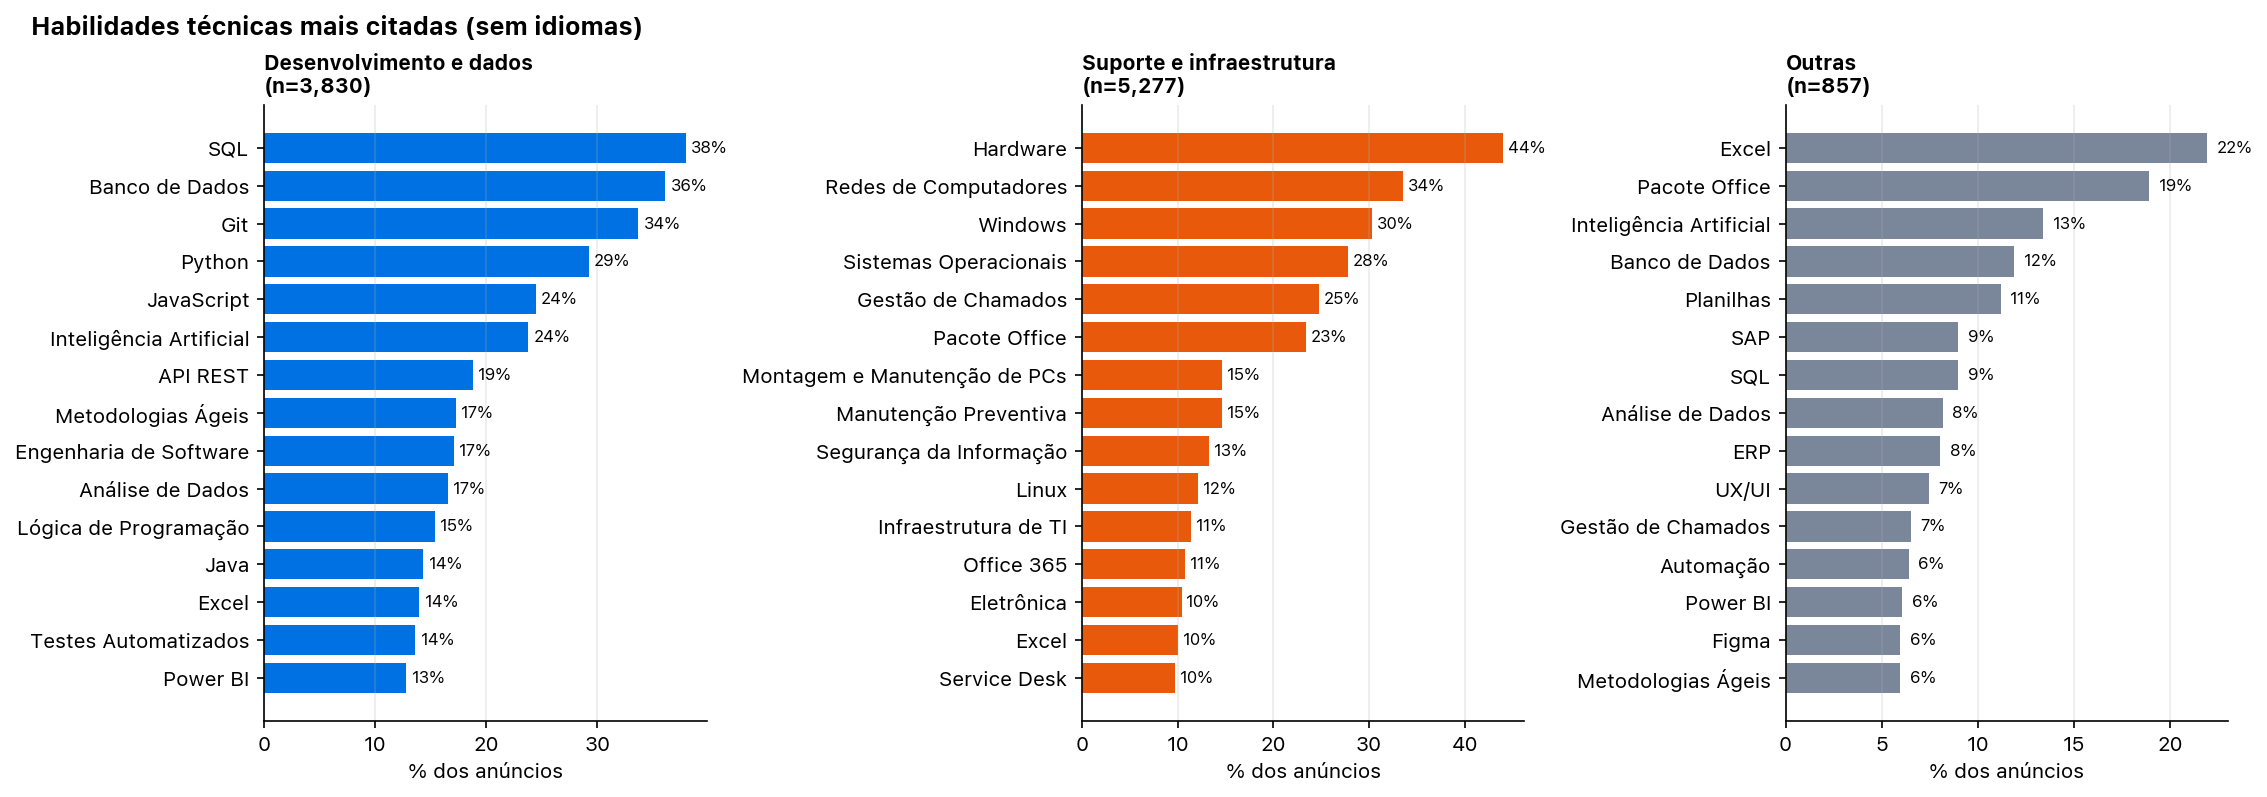

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, g in zip(axes, L.ORDEM_GRUPOS):
    s = df[df.grupo == g]
    c = s["sk_tec"].explode().value_counts().head(15)[::-1] / len(s) * 100
    ax.barh(c.index, c.values, color=L.PALETA[g])
    for i, v in enumerate(c.values): ax.text(v + .5, i, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_title(f"{g}\n(n={len(s):,})", fontsize=10); ax.grid(axis="y", visible=False); ax.set_xlabel("% dos anúncios")
fig.suptitle("Habilidades técnicas mais citadas (sem idiomas)", x=.01, ha="left", fontweight="bold")
L.salvar(fig, "02_top_tecnicas"); plt.show()

## 7. Conceitos × ferramentas (diálogo com Dobslaw et al., 2023)

Dobslaw et al. observaram que os documentos acadêmicos enfatizam **conceitos** e os anúncios enfatizam **tecnologias**.
Aqui, a taxonomia do projeto é dividida em duas listas. **A classificação é uma proposta desta análise e precisa ser validada**:
*conceitos* = fundamentos (lógica, algoritmos, redes, SO...); *ferramentas* = linguagens, frameworks, bancos específicos e ferramentas de nuvem/DevOps.

Conceitos (n=21),Ferramentas (n=108)
Algoritmos,.NET
Análise de Dados,ABAP
Banco de Dados,AWS
Cibersegurança,AWS SQS
Clean Code,AZ-900 (Azure Fundamentals)
DDD,Angular
Design Patterns,Ansible
Engenharia de Software,Apex
Estatística,ArgoCD
Estrutura de Dados,Assembly


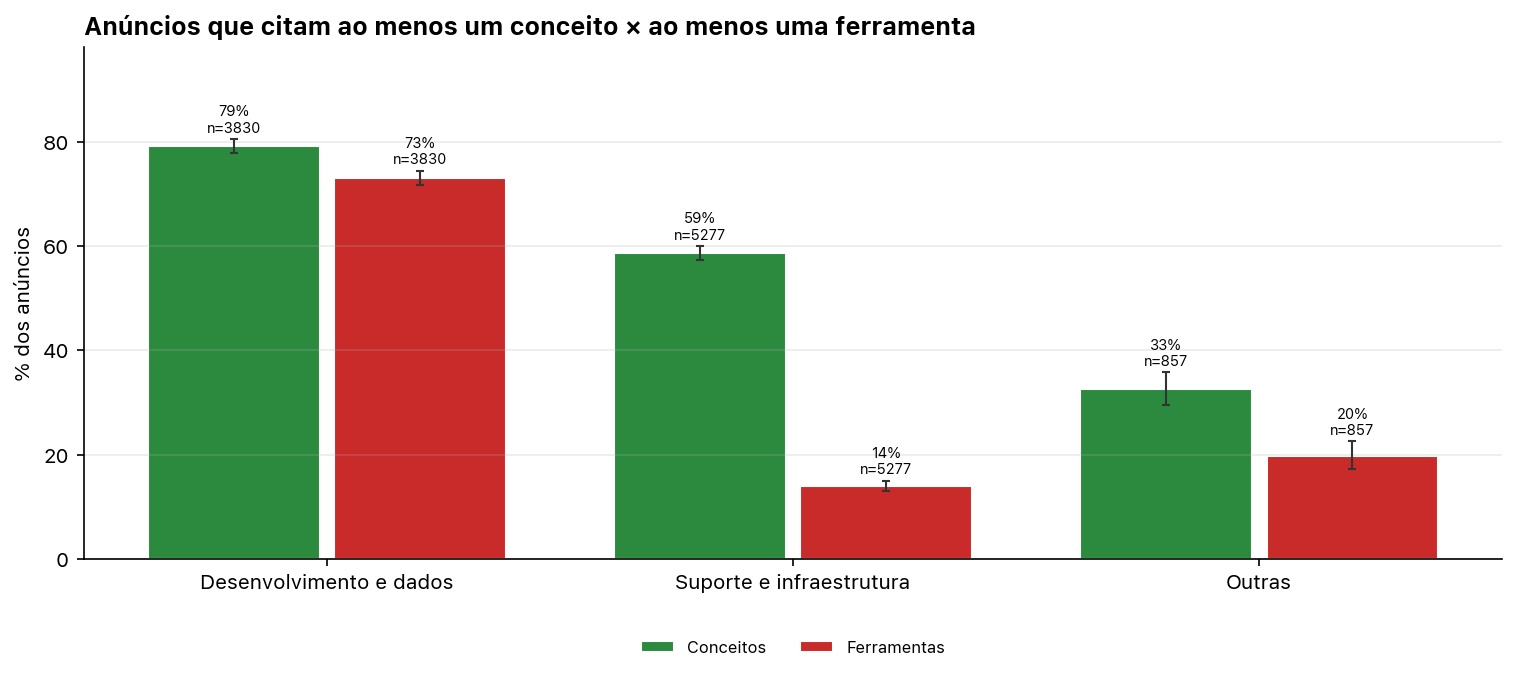

,média de conceitos/anúncio,média de ferramentas/anúncio
grupo,,
Desenvolvimento e dados,1.80,3.60
Suporte e infraestrutura,0.96,0.31
Outras,0.48,0.45


In [8]:
CONCEITOS, FERRAMENTAS = L.CONCEITOS, L.FERRAMENTAS   # definidos em analise_lib.py (mesma lista usada no notebook 05)
display(pd.DataFrame({"Conceitos (n=%d)" % len(CONCEITOS): pd.Series(sorted(CONCEITOS)),
                      "Ferramentas (n=%d)" % len(FERRAMENTAS): pd.Series(sorted(FERRAMENTAS))}).fillna("").style.hide(axis="index").set_properties(**{"font-size": "10px", "text-align": "left"}))

df["n_conc"] = df["sk_tec"].apply(lambda l: sum(s in CONCEITOS for s in l))
df["n_ferr"] = df["sk_tec"].apply(lambda l: sum(s in FERRAMENTAS for s in l))
df["tem_conc"] = df["n_conc"] > 0; df["tem_ferr"] = df["n_ferr"] > 0
tc = L.tabela_prop(df, "tem_conc", ["grupo"]).assign(tipo="Conceitos"); tf_ = L.tabela_prop(df, "tem_ferr", ["grupo"]).assign(tipo="Ferramentas")
pd.concat([tc, tf_]).to_csv(L.BASE / "tabela_02_conceito_ferramenta.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.4))
L.barras_prop(ax, pd.concat([tc, tf_]), "grupo", "tipo", L.ORDEM_GRUPOS, ["Conceitos", "Ferramentas"], {"Conceitos": "#2B8A3E", "Ferramentas": "#C92A2A"})
ax.set_title("Anúncios que citam ao menos um conceito × ao menos uma ferramenta"); ax.set_xlabel("")
L.salvar(fig, "02_conceito_ferramenta"); plt.show()
rt = df.groupby("grupo")[["n_conc", "n_ferr"]].mean().reindex(L.ORDEM_GRUPOS).round(2)
display(rt.rename(columns={"n_conc": "média de conceitos/anúncio", "n_ferr": "média de ferramentas/anúncio"}))

## 8. Por área (competências-chave, áreas com n ≥ 50)

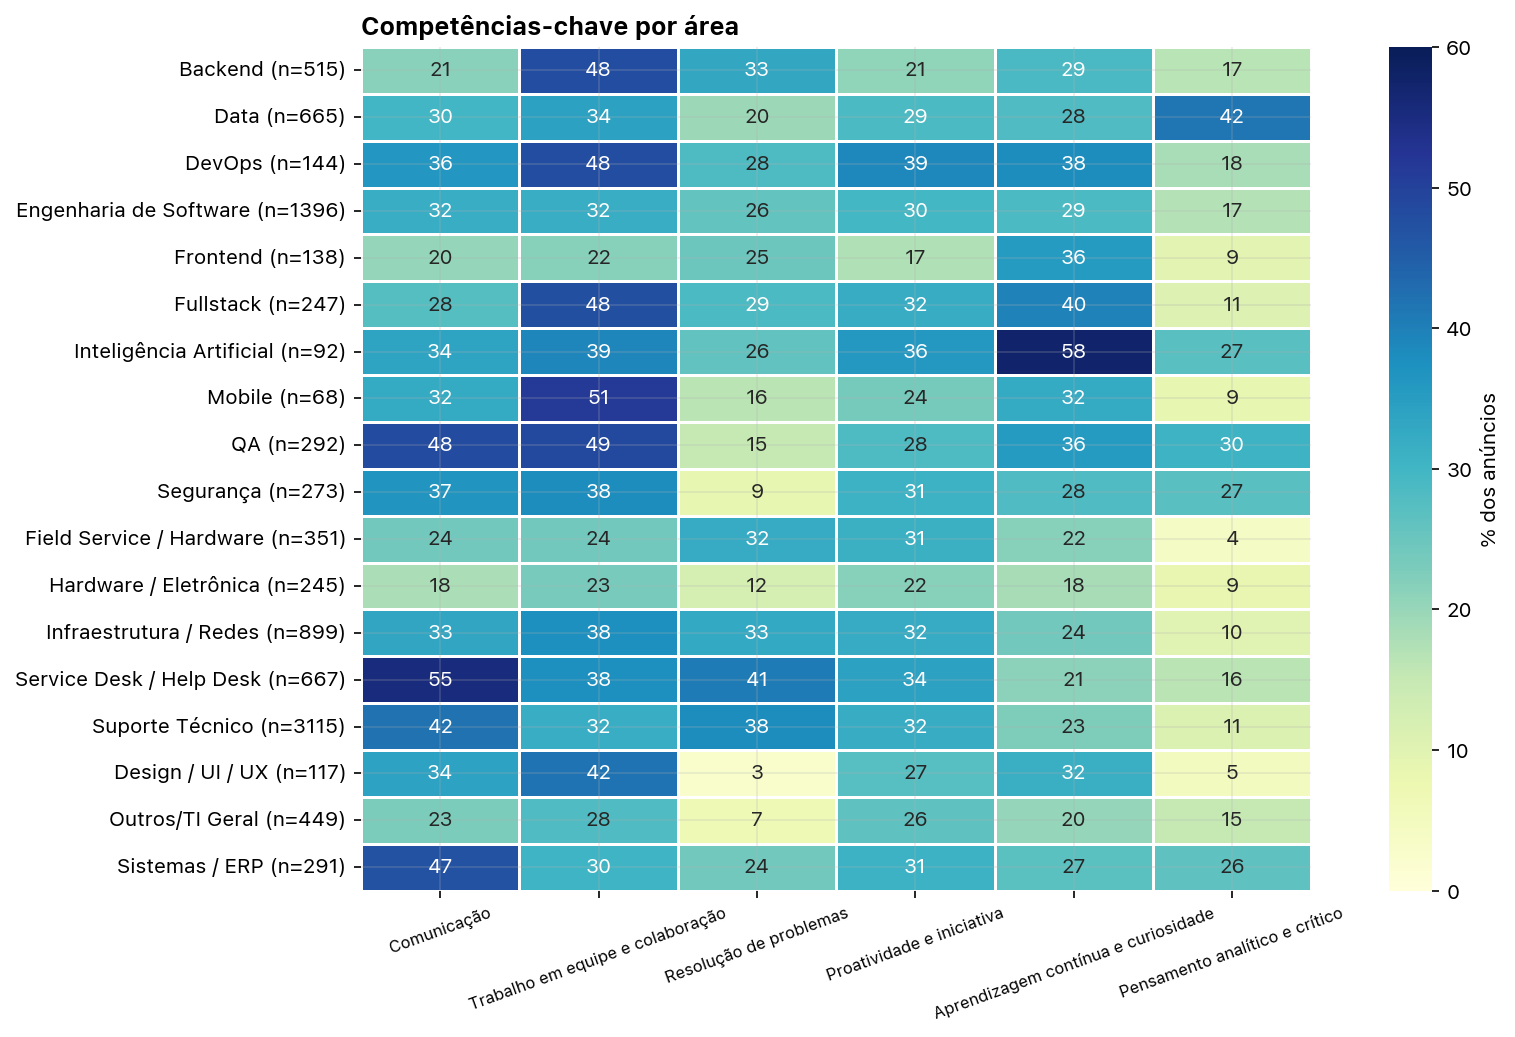

In [9]:
chave = ["comunicacao", "trabalho_equipe", "resolucao_problemas", "proatividade", "aprendizagem_continua", "pensamento_analitico"]
areas = df["area"].astype(str).value_counts(); areas = areas[areas >= 50].index
ma = pd.DataFrame({ROT[k]: [100 * df[df.area == a][f"c_{k}"].mean() for a in areas] for k in chave}, index=[f"{a} (n={(df.area == a).sum()})" for a in areas])
ma = ma.loc[sorted(ma.index, key=lambda x: (L.ORDEM_GRUPOS.index(L.grupo_da_area(x.rsplit(' (n=', 1)[0])), x))]
fig, ax = plt.subplots(figsize=(10, 6.8))
sns.heatmap(ma, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=60, linewidths=.5, cbar_kws={"label": "% dos anúncios"}, ax=ax)
ax.set_title("Competências-chave por área"); ax.tick_params(axis="x", labelsize=8, rotation=20)
L.salvar(fig, "02_competencias_por_area"); plt.show()

## 9. Extensão proposta (não prevista no artigo): autorregulação e abertura a feedback

A Seção 2.1 define a dimensão metacognitiva como incluindo "reflexão sobre a própria aprendizagem" e "autorregulação", mas o dicionário
da Seção 3.4 só tem *aprendizagem contínua e curiosidade*. Se as autoras quiserem manter a definição ampla, falta cobertura.
Abaixo, um teste exploratório com termos como *feedback, autocrítica, autodisciplina*. **Não entra nos resultados principais.**

In [10]:
ext = pd.DataFrame({
    "Aprendizagem contínua e curiosidade (no artigo)": [100 * df[df.grupo == g]["c_aprendizagem_continua"].mean() for g in L.ORDEM_GRUPOS],
    "Autorregulação / feedback (extensão)": [100 * df[df.grupo == g]["c_autorregulacao"].mean() for g in L.ORDEM_GRUPOS],
}, index=L.ORDEM_GRUPOS).round(1)
display(ext.style.set_caption("% dos anúncios"))
ex = df[df.c_autorregulacao].sample(6, random_state=3)
display(pd.DataFrame([{"Área": r["area"], "Trecho": L.trecho(r["texto"], m.start(), m.end(), 100)}
                      for _, r in ex.iterrows() for m in [re.search(L.EXTENSAO_METACOGNITIVA["autorregulacao"][2], r["tf"])] if m]).style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))

,Aprendizagem contínua e curiosidade (no artigo),Autorregulação / feedback (extensão)
Desenvolvimento e dados,31.300000,9.100000
Suporte e infraestrutura,22.400000,2.500000
Outras,24.000000,5.400000


Área,Trecho
Segurança,"…as quanto para graduação, pós-graduação e cursos livres, Plano de Desenvolvimento Individual (PDI), feedbacks constantes, Programa de Mentoria, eventos internos, subsídio para treinamentos, universidade corpor…"
Suporte Técnico,"…soluções em clientes, contribuindo com o suporte técnico e operacional; Melhoria contínua: Coletar feedbacks dos clientes, identificando oportunidades de melhoria e novas soluções. Hard skills: Curso superior…"
Fullstack,"…ndo os padrões do time; Participar de reuniões de acompanhamento e revisões de código, aplicando os feedbacks recebidos; Utilizar ferramentas de IA como apoio às atividades, revisando os resultados com orienta…"
Engenharia de Software,…vaga após a conclusão do curso (caso ainda esteja na faculdade). Boas habilidades de comunicação e autogestão. Como o programa funciona? Nossa missão será te auxiliar em seu desenvolvimento e garantir a flexib…
Service Desk / Help Desk,…e serviços da empresa; Treinamentos e desenvolvimento contínuo; Ambiente colaborativo e acolhedor; Feedbacks frequentes e plano de desenvolvimento; Incentivo à inovação e criatividade. Tipo de contrato: CLT –…
Backend,"…rosserviços, WebSockets e serviços AWS Capacidade de investigar problemas, pedir contexto e aplicar feedback Você não precisa dominar todas as tecnologias do stack antes de se candidatar. Procuramos uma base…"


## 10. Risco de falsos positivos do dicionário (diagnóstico)

Um dos riscos citados na Seção 3.6-d é capturar texto **institucional** ("nossa equipe valoriza o trabalho em equipe") em vez de
um requisito. Um indicador indireto: a proporção de ocorrências **antes do primeiro título de requisitos/atividades**,
no subconjunto de anúncios onde esse título foi detectado. **Isto não é precisão**, é um alerta para guiar a validação humana.

Anúncios com título de requisitos/atividades detectado: 68.5% (o diagnóstico vale só para eles)


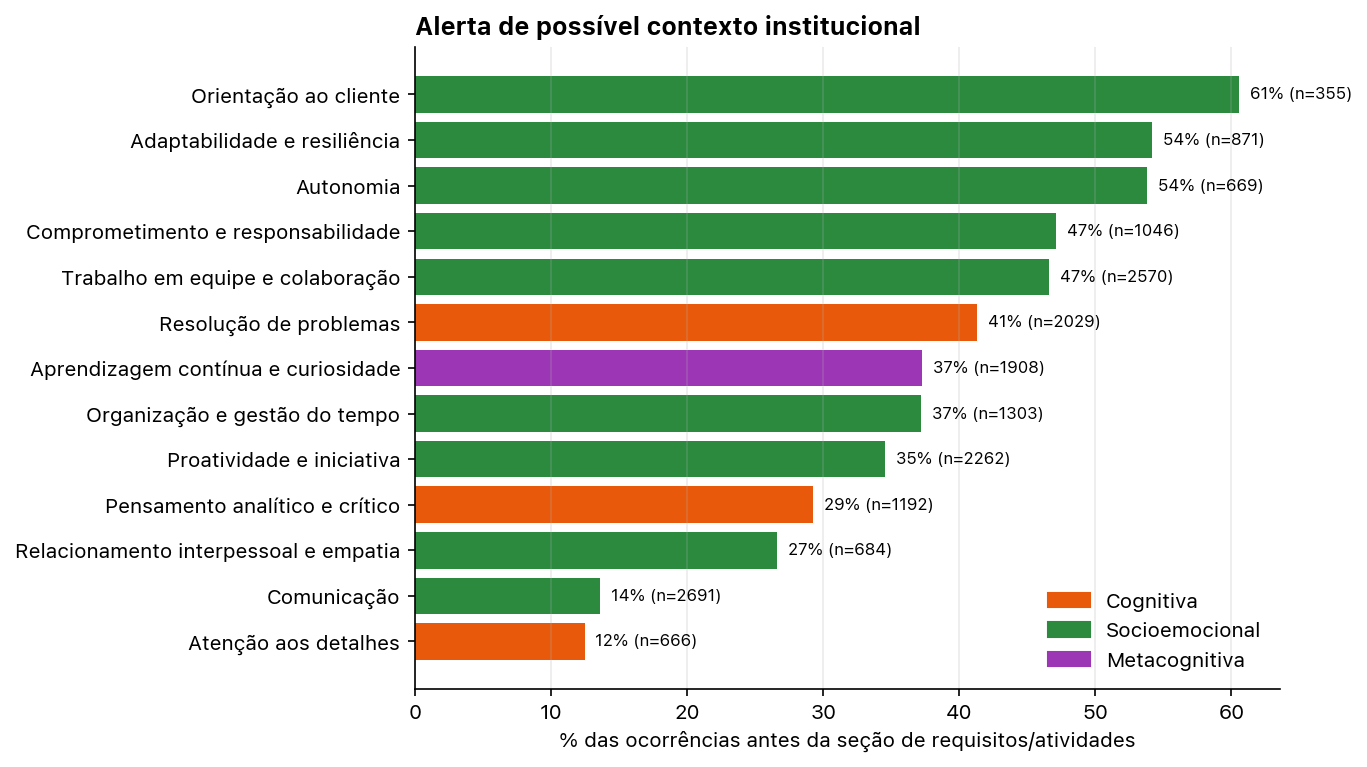

In [11]:
tem = df["pos_secao_vaga"] > 0
print(f"Anúncios com título de requisitos/atividades detectado: {tem.mean():.1%} (o diagnóstico vale só para eles)")
rows = []
for k in CHAVES:
    m = df[f"c_{k}"] & tem
    rows.append({"competencia": ROT[k], "dimensao": DIM[k], "n": int(m.sum()), "pct_antes": 100 * df.loc[m, f"pre_{k}"].mean()})
dg = pd.DataFrame(rows).sort_values("pct_antes")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(dg["competencia"], dg["pct_antes"], color=[cd.get(d, "#888") for d in dg["dimensao"]])
for i, (_, r) in enumerate(dg.iterrows()): ax.text(r["pct_antes"] + .8, i, f"{r['pct_antes']:.0f}% (n={r['n']})", va="center", fontsize=8)
ax.set_xlabel("% das ocorrências antes da seção de requisitos/atividades"); ax.set_title("Alerta de possível contexto institucional"); ax.grid(axis="y", visible=False)
ax.legend(handles=[mp.Patch(color=cd[d], label=d) for d in (L.COG, L.SOC, L.MET)], loc="lower right")
L.salvar(fig, "02_diagnostico_falsos_positivos"); plt.show()

## 11. Planilha de validação do dicionário (`[P11]`)
15 trechos aleatórios por competência (como descrito na Seção 3.4), prontos para duas leitoras indicarem se **a competência é realmente solicitada ao candidato**.
Depois de preenchida, a precisão por competência = (nº de "sim") / 15, e o kappa mede a concordância entre as duas leitoras.

In [12]:
rng = np.random.default_rng(2026)
linhas = []
for k in CHAVES:
    rx = re.compile(L.COMPETENCIAS[k][2])
    pool = df[df[f"c_{k}"]]
    s = pool.sample(min(15, len(pool)), random_state=int(rng.integers(1e6)))
    for _, r in s.iterrows():
        m = rx.search(r["tf"])
        linhas.append({"competencia": ROT[k], "dimensao": DIM[k], "id_anuncio": f"{r['fonte']}:{r['external_id']}", "area": r["area"], "nivel": r["nivel"],
                       "trecho": L.trecho(r["texto"], m.start(), m.end(), 160), "termo_capturado": r["texto"][m.start():m.end()],
                       "ocorre_antes_secao_requisitos": bool(r[f"pre_{k}"]),
                       "solicitada_ao_candidato_leitora1 (sim/nao)": "", "solicitada_ao_candidato_leitora2 (sim/nao)": "", "observacao": ""})
val = pd.DataFrame(linhas)
val.to_csv(L.BASE / "validacao_dicionario_amostra.csv", index=False, encoding="utf-8-sig")
print(f"Planilha salva: validacao_dicionario_amostra.csv ({len(val)} linhas, {val['competencia'].nunique()} competências)")
display(val.groupby("competencia").head(2)[["competencia", "area", "nivel", "termo_capturado", "trecho"]].style.hide(axis="index")
        .set_properties(**{"text-align": "left", "font-size": "11px"}))

Planilha salva: validacao_dicionario_amostra.csv (195 linhas, 13 competências)


competencia,area,nivel,termo_capturado,trecho
Resolução de problemas,QA,Júnior,resolução de problema,…e. Atenção aos detalhes. Organização e responsabilidade com as entregas. Boa comunicação e facilidade para trabalhar em equipe. Proatividade na identificação e resolução de problemas. Curiosidade e interesse em aprender novas tecnologias. Capacidade de trabalhar em um ambiente ágil e dinâmico. Senso de responsabilidade sobre a qualidade da…
Resolução de problemas,Infraestrutura / Redes,Júnior,resolução de problema,"…cal (presencial) e remoto aos colaboradores, utilizando ferramentas como AnyDesk para diagnósticos ágeis. Infraestrutura e Redes: Configuração, monitoramento e resolução de problemas em redes locais (cabeamento estruturado, roteadores, switches e Wi-Fi). Parque de Máquinas e Periféricos: Manutenção preventiva e corretiva de desktops e note…"
Pensamento analítico e crítico,Data,Júnior,Raciocínio lógico,"…Conhecimento em Power BI; 🔹 Conhecimento em Machine Learning, LLMs (modelos de linguagem) e OCR (extração de texto de documentos e imagens). 👉🏻 Competências: 🔹 Raciocínio lógico e pensamento analítico; 🔹 Pensamento crítico e capacidade de resolver problemas; 🔹 Interpretação de dados e gráficos; 🔹 Atenção aos detalhes; 🔹 Curiosidade e a…"
Pensamento analítico e crítico,Service Desk / Help Desk,Júnior,Perfil analítico,"…mo Analista de Service Desk ou Suporte Técnico com atuação em atendimento N1/N2. Boa comunicação verbal e escrita para interação com usuários e áreas técnicas; Perfil analítico e organizado, com foco em resultados e melhoria contínua; Resiliência e habilidade para lidar com situações de pressão e demandas simultâneas; Foco no cliente…"
Atenção aos detalhes,Suporte Técnico,Júnior,atenção aos detalhes,"…s perfis; Saiba transformar uma explicação técnica em uma orientação simples; Seja organizado com chamados, inventários e registros; Tenha postura preventiva e atenção aos detalhes; Consiga manter a calma diante de imprevistos; Seja discreto e responsável no tratamento de informações e equipamentos; Tenha iniciativa para propor melhorias;…"
Atenção aos detalhes,Suporte Técnico,Júnior,Atenção aos detalhes,…onhecimento. Competências comportamentais Comunicação; Proatividade; Organização; Responsabilidade; Pensamento analítico; Capacidade de resolução de problemas; Atenção aos detalhes; Agilidade; Senso de prioridade; Paciência no atendimento aos usuários; Trabalho em equipe; Capacidade de aprendizado contínuo; Comprometimento com prazos; Pos…
Comunicação,Suporte Técnico,Júnior,habilidades de comunicação,"…básico em redes, manutenção de computadores e sistemas operacionais. Habilidade analítica para identificar e resolver problemas de forma eficiente. Excelentes habilidades de comunicação para interagir com diferentes níveis de usuários. Capacidade de gerenciar múltiplas tarefas simultaneamente e priorizar de acordo com a urgência."
Comunicação,Engenharia de Software,Júnior,Boa comunicação,"…de dados relacionais, preferencialmente MySQL; Capacidade de compreender e trabalhar com código existente, realizando ajustes e correções de forma estruturada; Boa comunicação para compartilhar o andamento das atividades, esclarecer dúvidas e sinalizar eventuais bloqueios."
Trabalho em equipe e colaboração,Data,Júnior,colaboração,"…uação: Conhecimento básico em SQL, Python e conceitos de Engenharia de Dados. Interesse em qualidade, governança e análise de dados. Capacidade de aprendizado, colaboração e atuação em ambiente orientado a dados. 🚀 E será um diferencial se você tiver: Familiaridade com Databricks e desenvolvimento de pipelines de dados. Conhecime…"
Trabalho em equipe e colaboração,Service Desk / Help Desk,Júnior,colaborativ,"…uar no atendimento e suporte aos usuários, garantindo agilidade, organização e qualidade na resolução de chamados técnicos. Procuramos profissionais com perfil colaborativo e foco em experiência do usuário e proficiência nos idiomas Português/Espanhol. Estamos com algumas posições em dive

## 12. Resumo exportável

In [13]:
res = []
for g in L.ORDEM_GRUPOS:
    for nv in L.NIVEIS_PRINCIPAIS:
        s = df[(df.grupo == g) & (df.nivel == nv)]
        for k in CHAVES:
            x, lo, hi = L.prop_ic(s[f"c_{k}"].sum(), len(s))
            res.append({"grupo": g, "nivel": nv, "competencia": ROT[k], "dimensao": DIM[k], "n": len(s), "pct": round(x, 1), "ic_lo": round(lo, 1), "ic_hi": round(hi, 1)})
pd.DataFrame(res).to_csv(L.BASE / "tabela_02_competencias.csv", index=False)
top = {g: [ROT[k] for k in sorted(CHAVES, key=lambda k: -df[df.grupo == g][f"c_{k}"].mean())[:3]] for g in L.ORDEM_GRUPOS}
Markdown("**Três competências mais frequentes por grupo (dicionário do artigo):**\n\n" + "\n".join(
    f"- {g}: " + ", ".join(f"{c} ({100*df[df.grupo==g]['c_'+[k for k in CHAVES if ROT[k]==c][0]].mean():.0f}%)" for c in top[g]) for g in L.ORDEM_GRUPOS))

**Três competências mais frequentes por grupo (dicionário do artigo):**

- Desenvolvimento e dados: Trabalho em equipe e colaboração (38%), Aprendizagem contínua e curiosidade (31%), Comunicação (31%)
- Suporte e infraestrutura: Comunicação (40%), Resolução de problemas (36%), Trabalho em equipe e colaboração (33%)
- Outras: Comunicação (33%), Trabalho em equipe e colaboração (31%), Proatividade e iniciativa (28%)

### Como interpretar
- Frequências altas de **comunicação** ou **trabalho em equipe** descrevem o que os anúncios *declaram*; não provam que a exigência cresceu ou que decorre da IA.
- Diferenças entre grupos devem ser lidas **após a padronização por tamanho do texto** (seção 3).
- Antes de publicar percentuais, é indispensável preencher a planilha de validação (seção 11) e relatar a precisão por competência.
- A classificação conceito × ferramenta (seção 7) e a exclusão de idiomas da dimensão técnica são **escolhas desta análise**, a validar com a orientadora.